In [82]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd  
import requests  
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, roc_curve, auc, accuracy_score, precision_score, recall_score, f1_score
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier, BaggingClassifier
from sklearn.svm import SVC
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

# Load breast cancer dataset from sklearn
data = load_breast_cancer()

# Split the data into features (X) and target (y)
X = data.data
y = data.target

# Split the data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

In [86]:
# Define the URL of the dataset
url = "https://archive.ics.uci.edu/ml/machine-learning-databases/breast-cancer-wisconsin/breast-cancer-wisconsin.data"

# Download the content of the URL
response = requests.get(url)

# Check if the request was successful
if response.status_code == 200:
    # Read the CSV data
    data = pd.read_csv(url, header=None)
    # Define column names for better readability
    column_names = ['Sample Number', 'Clump Thickness', 'Uniformity of Cell Size', 
                    'Uniformity of Cell Shape', 'Marginal Adhesion', 'Single Epithelial Cell Size', 
                    'Bare Nuclei', 'Bland Chromatin', 'Normal Nucleoli', 'Mitoses', 'Class']
    data.columns = column_names
    
    # Select required columns and preprocess the target variable
    data = data.iloc[:, [1, 4, 5, 6, 8, 10]]
    data['Class'] = data['Class'].replace({2: 0, 4: 1})
    
    print("Data imported successfully!")
else:
    print("Error retrieving data. HTTP status code:", response.status_code) 

Data imported successfully!


In [ ]:
data.head()

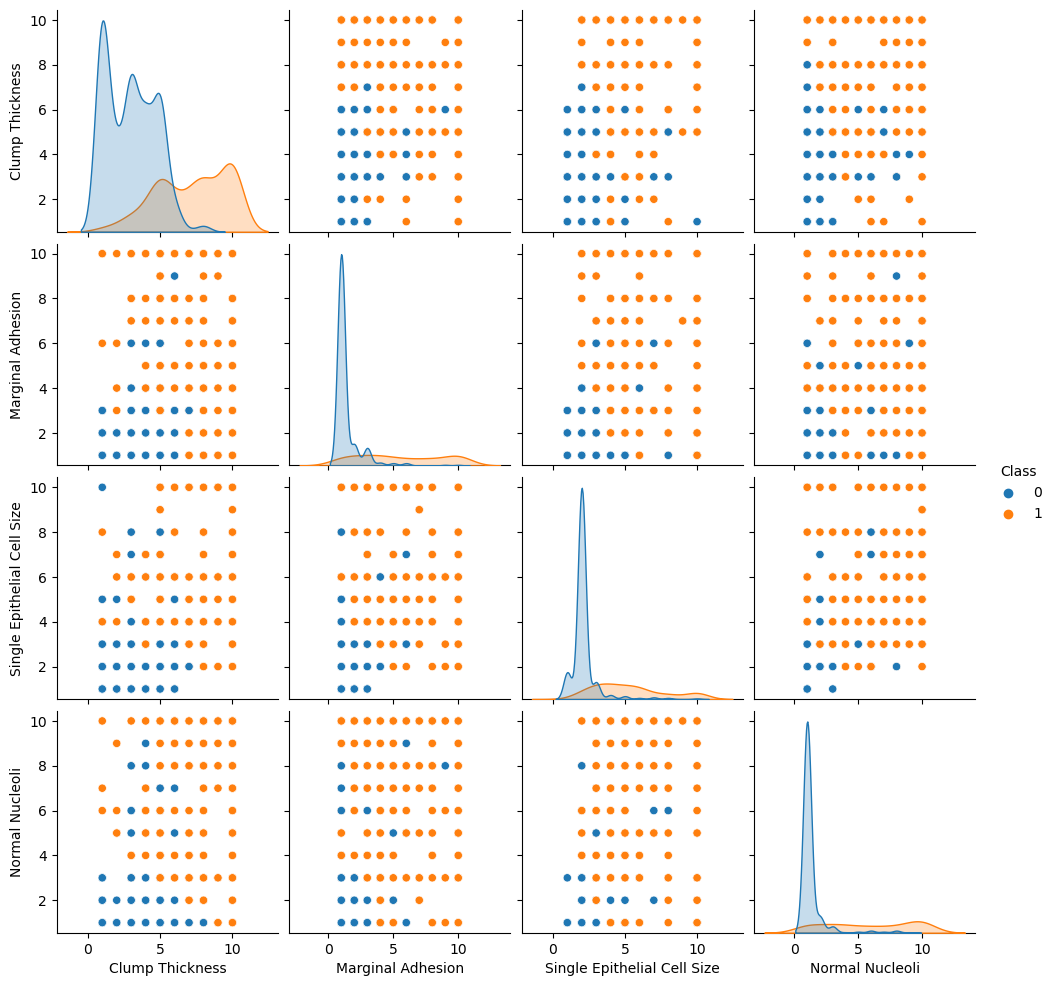

In [59]:
# Select specific columns for analysis
selected_columns = ['Clump Thickness', 'Marginal Adhesion', 'Single Epithelial Cell Size', 
                    'Bare Nuclei', 'Normal Nucleoli', 'Class']

# Create a DataFrame with only the selected columns
selected_data = data[selected_columns]

# Visualize pairwise relationships with pairplot
sns.pairplot(selected_data, hue='Class', diag_kind='kde')
plt.show() 


In [87]:
# Define base classifier (KNeighborsClassifier)
base_classifier = KNeighborsClassifier()

# Define Bagging classifier with base classifier
bagging_classifier = BaggingClassifier(base_classifier, n_estimators=10, random_state=42)

# Define models dictionary with Bagging classifier
models = {
    "Bagging (KNeighbors)": bagging_classifier,
    "Random Forest": RandomForestClassifier(random_state=42),
    "SVC": make_pipeline(StandardScaler(), SVC(probability=True, random_state=42))
}
# Train the models and evaluate
results = {}
for name, model in models.items():
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    y_proba = model.predict_proba(X_test)[:, 1]
    cm = confusion_matrix(y_test, y_pred)
    fpr, tpr, _ = roc_curve(y_test, y_proba)
    roc_auc = auc(fpr, tpr)
    results[name] = (cm, fpr, tpr, roc_auc)



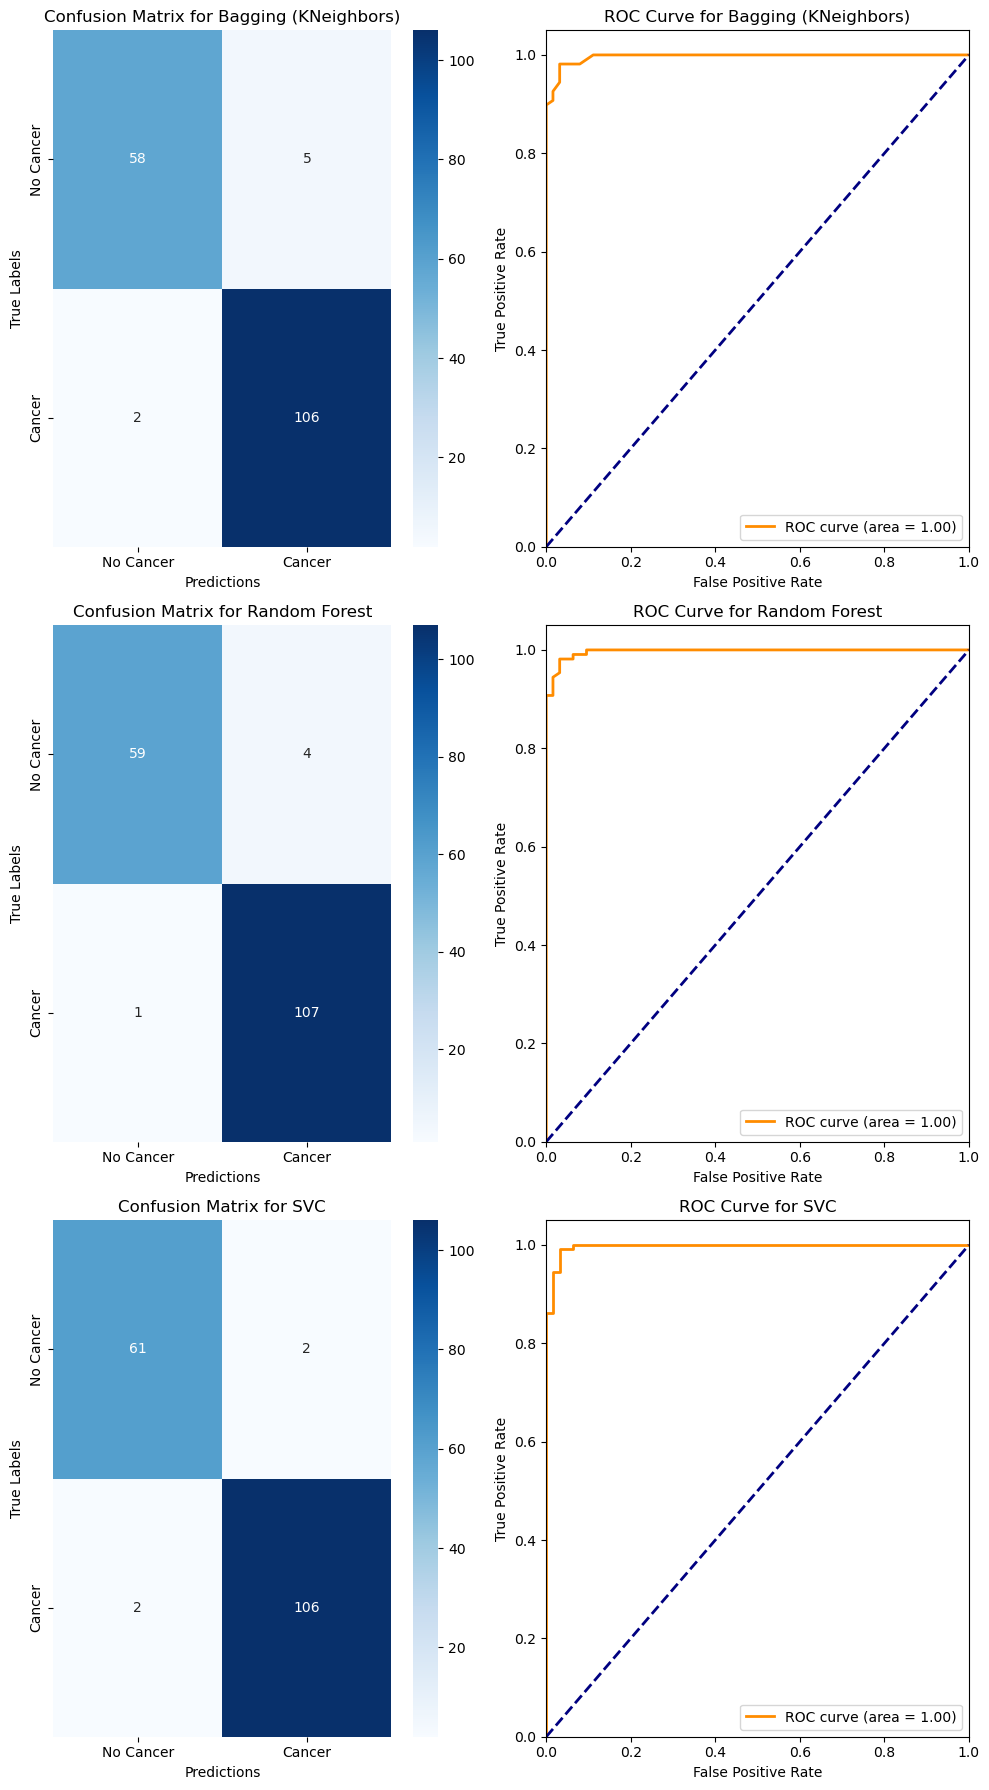

In [88]:

# Visualize the results
fig, axes = plt.subplots(nrows=len(models), ncols=2, figsize=(10, 18))
for idx, (name, (cm, fpr, tpr, roc_auc)) in enumerate(results.items()):
    sns.heatmap(cm, annot=True, fmt="d", cmap='Blues', ax=axes[idx, 0], xticklabels=['No Cancer', 'Cancer'], yticklabels=['No Cancer', 'Cancer'])
    axes[idx, 0].set_title(f'Confusion Matrix for {name}')
    axes[idx, 0].set_xlabel('Predictions')
    axes[idx, 0].set_ylabel('True Labels')
    
    axes[idx, 1].plot(fpr, tpr, label=f'ROC curve (area = {roc_auc:.2f})', color='darkorange', lw=2)
    axes[idx, 1].plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
    axes[idx, 1].set_xlim([0.0, 1.0])
    axes[idx, 1].set_ylim([0.0, 1.05])
    axes[idx, 1].set_xlabel('False Positive Rate')
    axes[idx, 1].set_ylabel('True Positive Rate')
    axes[idx, 1].set_title(f'ROC Curve for {name}')
    axes[idx, 1].legend(loc="lower right")

plt.tight_layout()
plt.show()

In [89]:
# Compute and print evaluation metrics for each method
for name, (cm, fpr, tpr, _) in results.items():
    # Compute true positives, true negatives, false positives, false negatives
    tp = cm[1, 1]
    tn = cm[0, 0]
    fp = cm[0, 1]
    fn = cm[1, 0]
    
    # Compute precision
    precision = tp / (tp + fp)
    
    # Compute recall
    recall = tp / (tp + fn)
    
    # Compute F1-score
    f1_score = 2 * (precision * recall) / (precision + recall)
    
    # Compute specificity
    specificity = tn / (tn + fp)
    
    # Compute balanced accuracy
    balanced_accuracy = (recall + specificity) / 2
    
    # Compute AUC-ROC
    roc_auc = auc(fpr, tpr)
    
    # Print evaluation metrics
    print(f"{name}:")
    print(f"Precision: {precision:.2f}")
    print(f"Recall: {recall:.2f}")
    print(f"F1-score: {f1_score:.2f}")
    print(f"Specificity: {specificity:.2f}")
    print(f"Balanced Accuracy: {balanced_accuracy:.2f}")
    print(f"AUC-ROC: {roc_auc:.2f}")
    print("\n")


Bagging (KNeighbors):
Precision: 0.95
Recall: 0.98
F1-score: 0.97
Specificity: 0.92
Balanced Accuracy: 0.95
AUC-ROC: 1.00


Random Forest:
Precision: 0.96
Recall: 0.99
F1-score: 0.98
Specificity: 0.94
Balanced Accuracy: 0.96
AUC-ROC: 1.00


SVC:
Precision: 0.98
Recall: 0.98
F1-score: 0.98
Specificity: 0.97
Balanced Accuracy: 0.97
AUC-ROC: 1.00




In [90]:
# Predictions after majority voting for Bagging (KNeighbors)
final_predictions_bagging = bagging_classifier.predict(X_test)

# Predictions after majority voting for Random Forest
final_predictions_rf = models["Random Forest"].predict(X_test)

# Predictions after majority voting for SVC
final_predictions_svc = models["SVC"].predict(X_test)



# Calculate the majority result for Bagging (KNeighbors)
majority_result_bagging = mode(final_predictions_bagging)[0][0]

# Calculate the majority result for Random Forest
majority_result_rf = mode(final_predictions_rf)[0][0]

# Calculate the majority result for SVC
majority_result_svc = mode(final_predictions_svc)[0][0]

# Display the majority result for each model
print("Final Predictions after Majority Voting:\n")
print("Bagging (KNeighbors):", final_predictions_bagging)
print("Majority Result for Bagging (KNeighbors):", majority_result_bagging)
print("Random Forest:", final_predictions_rf)
print("Majority Result for Random Forest:", majority_result_rf)
print("SVC:", final_predictions_svc)
print("Majority Result for SVC:", majority_result_svc)



Final Predictions after Majority Voting:

Bagging (KNeighbors): [0 0 0 1 1 0 0 0 1 1 1 0 1 0 1 0 1 1 1 0 1 1 0 1 1 1 1 1 1 0 1 1 1 1 1 1 0
 1 0 1 1 0 1 1 1 1 1 1 1 1 0 0 1 1 1 1 1 0 1 1 1 0 0 1 1 1 0 0 1 1 1 0 1 0
 1 1 1 1 1 1 0 1 1 0 0 0 0 0 1 1 1 1 1 1 1 1 0 0 1 0 0 1 0 0 1 1 1 0 1 1 0
 1 1 0 1 0 1 1 1 0 1 1 1 0 1 0 0 1 1 0 0 0 1 1 0 0 1 1 1 0 1 0 1 1 0 1 0 0
 0 1 0 1 1 1 1 0 0 1 1 1 1 1 1 1 0 1 1 1 1 0 1]
Majority Result for Bagging (KNeighbors): 1
Random Forest: [1 0 0 1 1 0 0 0 0 1 1 0 1 0 1 0 1 1 1 0 1 1 0 1 1 1 1 1 1 0 1 1 1 1 1 1 0
 1 0 1 1 0 1 1 1 1 1 1 1 1 0 0 1 1 1 1 1 0 0 1 1 0 0 1 1 1 0 0 1 1 0 0 1 0
 1 1 1 1 1 1 0 1 1 0 0 0 0 0 1 1 1 1 1 1 1 1 0 0 1 0 0 1 0 0 1 1 1 0 1 1 0
 1 1 0 1 0 1 1 1 0 1 1 1 0 1 0 0 1 1 0 0 0 1 1 1 0 1 1 1 0 1 0 1 1 0 1 0 0
 0 1 0 1 1 1 1 0 0 1 1 1 1 1 1 1 1 1 1 1 1 0 1]
Majority Result for Random Forest: 1
SVC: [1 0 0 1 1 0 0 0 0 1 1 0 1 0 1 0 1 1 1 0 1 1 0 1 1 1 1 1 1 0 1 1 1 1 1 1 0
 1 0 1 1 0 1 1 1 1 1 1 1 1 0 0 1 1 1 1 1 0 0 1 1 0 0 1 1 1 0 0 1

C:\Users\adil\AppData\Local\Temp\ipykernel_14748\3897865144.py:13: FutureWarning: Unlike other reduction functions (e.g. `skew`, `kurtosis`), the default behavior of `mode` typically preserves the axis it acts along. In SciPy 1.11.0, this behavior will change: the default value of `keepdims` will become False, the `axis` over which the statistic is taken will be eliminated, and the value None will no longer be accepted. Set `keepdims` to True or False to avoid this warning.
  majority_result_bagging = mode(final_predictions_bagging)[0][0]
C:\Users\adil\AppData\Local\Temp\ipykernel_14748\3897865144.py:16: FutureWarning: Unlike other reduction functions (e.g. `skew`, `kurtosis`), the default behavior of `mode` typically preserves the axis it acts along. In SciPy 1.11.0, this behavior will change: the default value of `keepdims` will become False, the `axis` over which the statistic is taken will be eliminated, and the value None will no longer be accepted. Set `keepdims` to True or False

In [91]:
from scipy.stats import mode

# Perform majority voting to get the final prediction
final_prediction_majority_vote = mode(all_predictions, axis=0, keepdims=True)[0][0]

# Display the final prediction after majority voting
print("Final Prediction after Majority Voting:", final_prediction_majority_vote)

# Count the number of 1s and 0s in the final prediction
count_ones = np.count_nonzero(final_prediction_majority_vote == 1)
count_zeros = np.count_nonzero(final_prediction_majority_vote == 0)

# Determine the majority
if count_ones > count_zeros:
    majority_result = 1
else:
    majority_result = 0
# Display the majority result
print("Majority Result:", majority_result)


Final Prediction after Majority Voting: [1 0 0 1 1 0 0 0 0 1 1 0 1 0 1 0 1 1 1 0 1 1 0 1 1 1 1 1 1 0 1 1 1 1 1 1 0
 1 0 1 1 0 1 1 1 1 1 1 1 1 0 0 1 1 1 1 1 0 0 1 1 0 0 1 1 1 0 0 1 1 0 0 1 0
 1 1 1 1 1 1 0 1 1 0 0 0 0 0 1 1 1 1 1 1 1 1 0 0 1 0 0 1 0 0 1 1 1 0 1 1 0
 1 1 0 1 0 1 1 1 0 1 1 1 0 1 0 0 1 1 0 0 0 1 1 1 0 1 1 1 0 1 0 1 1 0 1 0 0
 0 1 0 1 1 1 1 0 0 1 1 1 1 1 1 1 0 1 1 1 1 0 1]
Majority Result: 1


In [95]:
from sklearn.metrics import accuracy_score

# True labels from the test set
true_labels = y_test

# Final predictions after majority voting
final_predictions = final_prediction_majority_vote

# Calculate accuracy
final_accuracy = accuracy_score(true_labels, final_predictions)

# Display final accuracy
print("Final Accuracy:", final_accuracy)


Final Accuracy: 0.9766081871345029


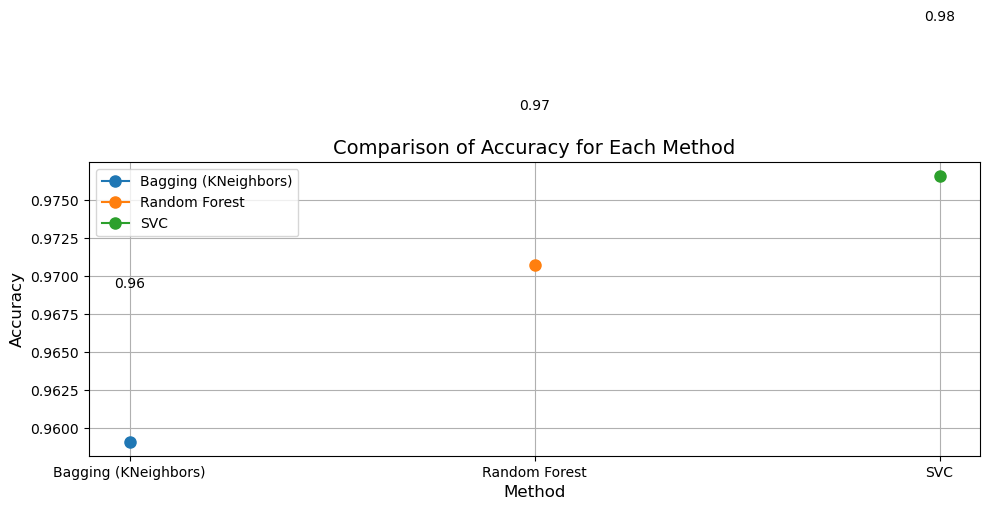

In [92]:
# Plot accuracy scores
methods = list(results.keys())
accuracy_scores = [((cm[0, 0] + cm[1, 1]) / np.sum(cm)) for _, (cm, _, _, _) in results.items()]

plt.figure(figsize=(10, 6))
for method, accuracy_score in zip(methods, accuracy_scores):
    plt.plot([method], [accuracy_score], marker='o', markersize=8, label=method)
    plt.text(method, accuracy_score + 0.01, f'{accuracy_score:.2f}', ha='center', va='bottom', fontsize=10)

plt.xlabel('Method', fontsize=12)
plt.ylabel('Accuracy', fontsize=12)
plt.title('Comparison of Accuracy for Each Method', fontsize=14)
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()



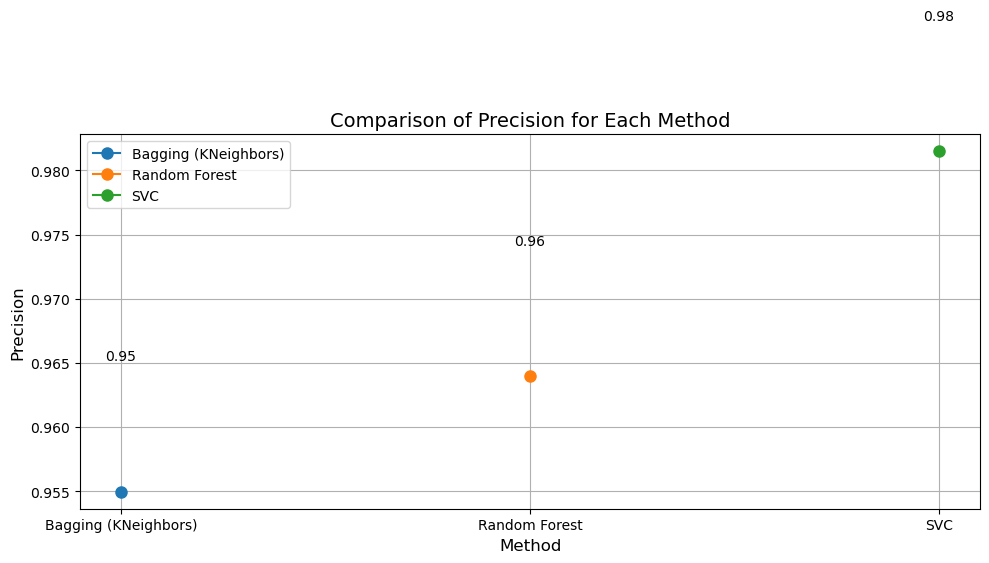

In [93]:
# Plot precision scores
precision_scores = [(cm[1, 1] / np.sum(cm[:, 1])) for _, (cm, _, _, _) in results.items()]

plt.figure(figsize=(10, 6))
for method, precision_score in zip(methods, precision_scores):
    plt.plot([method], [precision_score], marker='o', markersize=8, label=method)
    plt.text(method, precision_score + 0.01, f'{precision_score:.2f}', ha='center', va='bottom', fontsize=10)

plt.xlabel('Method', fontsize=12)
plt.ylabel('Precision', fontsize=12)
plt.title('Comparison of Precision for Each Method', fontsize=14)
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()